In [31]:
%run /Users/salmahirsi/Documents/GitHub/Politics-Network/src/milestone7a_votes_with_bills.py

import pandas as pd
stemmer = pd.read_csv("/Users/salmahirsi/Documents/GitHub/Politics-Network/data/processed/stemmer_2022_2026.csv")

# Hvad har en bestemt politiker stemt?
stemmer[stemmer["politiker"] == "Mette Frederiksen"][["dato", "sag_nummer", "titel_kort", "stemme"]]


# Hvad har en bestemt politiker stemt?
stemmer[stemmer["politiker"] == "Mette Frederiksen"][["dato", "sag_nummer", "titel_kort", "stemme"]]

# Søg på emne i titlen
stemmer[stemmer["titel_kort"].str.contains("klima|landbrug", case=False, na=False)]

Samlinger: 20221, 20222, 20231, 20241, 20251, 20252, 20261
emne
Økonomi, skat & energipriser        135
Klima, miljø & landbrug             129
Sundhed & psykiatri                 104
Retsvæsen & politi                  103
Ældre & velfærd                      93
Erhverv, finans & digitalisering     88
Andet                                83
Uddannelse & forskning               82
Udlændinge & integration             79
EU & udenrigs                        45
Beskæftigelse & arbejdsmarked        36
Grønland & Færøerne                  33
Transport & infrastruktur            32
Bolig                                30
Forsvar & sikkerhed                  27
Kultur, medier & kirke               27
Land & by                            17
1613 afstemninger fra 2022-11-16 til 2026-11-12
  stemmer hentet for 100/1613 afstemninger
  stemmer hentet for 200/1613 afstemninger
  stemmer hentet for 300/1613 afstemninger
  stemmer hentet for 400/1613 afstemninger
  stemmer hentet for 500/1613 afstem

,dato,samling,afstemning_id,sag_nummer,sagstype,emne,titel_kort,afstemningstype,vedtaget,aktør_id,politiker,parti,parti_nu,stemme
768,2022-12-22,20222,9015,L 10,Lovforslag,"Klima, miljø & landbrug",Om administration af den fælles landbrugspolitik m.v.,Endelig vedtagelse,True,15757,Aaja Chemnitz,IA,IA,Fravær
769,2022-12-22,20222,9015,L 10,Lovforslag,"Klima, miljø & landbrug",Om administration af den fælles landbrugspolitik m.v.,Endelig vedtagelse,True,18688,Aki-Matilda Høegh-Dam,N,N,Fravær
770,2022-12-22,20222,9015,L 10,Lovforslag,"Klima, miljø & landbrug",Om administration af den fælles landbrugspolitik m.v.,Endelig vedtagelse,True,18703,Alex Vanopslagh,LA,LA,Fravær
771,2022-12-22,20222,9015,L 10,Lovforslag,"Klima, miljø & landbrug",Om administration af den fælles landbrugspolitik m.v.,Endelig vedtagelse,True,20349,Anna Falkenberg,SP,SP,Fravær
772,2022-12-22,20222,9015,L 10,Lovforslag,"Klima, miljø & landbrug",Om administration af den fælles landbrugspolitik m.v.,Endelig vedtagelse,True,38,Astrid Krag,S,S,Fravær
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86622,2026-06-25,20252,10573,L 3,Lovforslag,Bolig,"Om samlet ejendomskategori for landbrugs-, skov og naturejendomme m.v.",Endelig vedtagelse,True,1845,Søren Gade,V,V,For
86623,2026-06-25,20252,10573,L 3,Lovforslag,Bolig,"Om samlet ejendomskategori for landbrugs-, skov og naturejendomme m.v.",Endelig vedtagelse,True,139,Thomas Danielsen,V,V,Fravær
86624,2026-06-25,20252,10573,L 3,Lovforslag,Bolig,"Om samlet ejendomskategori for landbrugs-, skov og naturejendomme m.v.",Endelig vedtagelse,True,118,Trine Bramsen,S,S,For
86625,2026-06-25,20252,10573,L 3,Lovforslag,Bolig,"Om samlet ejendomskategori for landbrugs-, skov og naturejendomme m.v.",Endelig vedtagelse,True,206,Troels Lund Poulsen,V,V,Fravær


dom
Uklart           21
Holder ikke      18
Holder           15
For lidt data     5
Name: count, dtype: int64

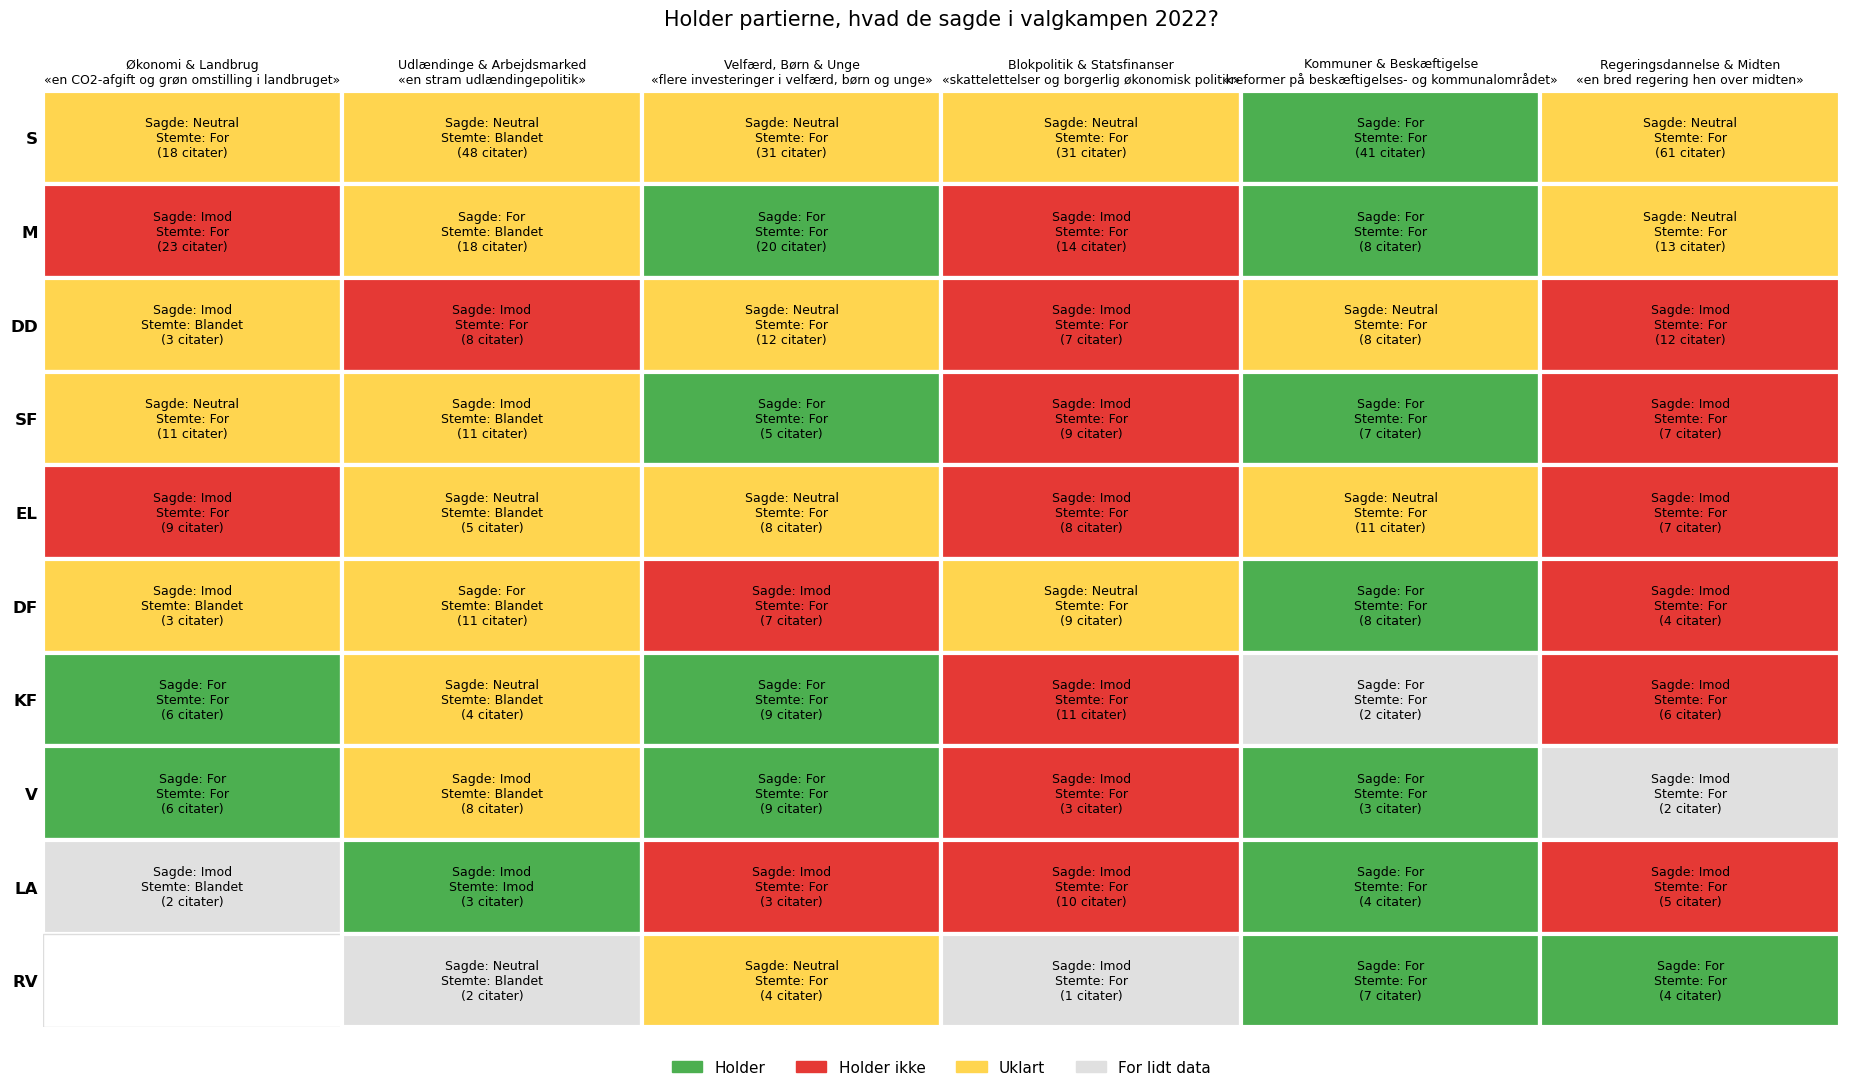

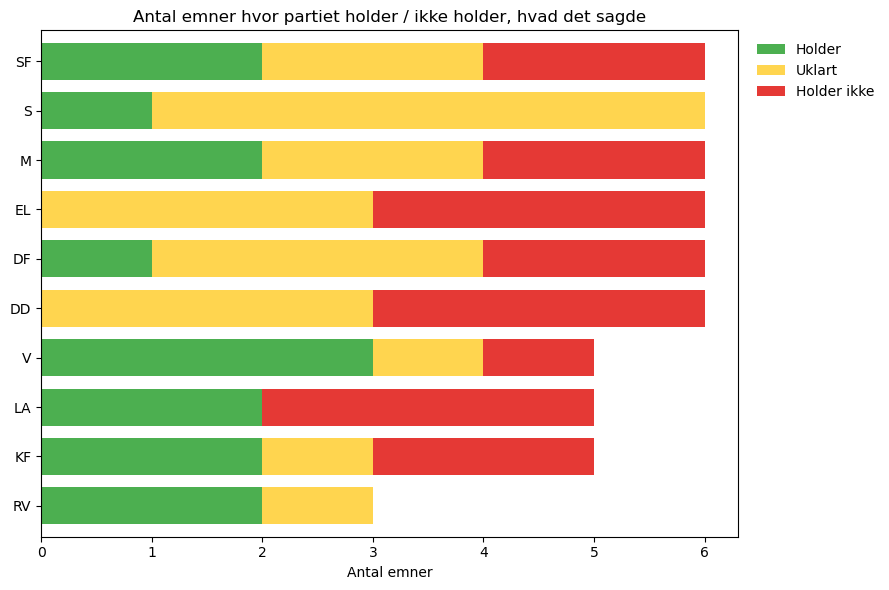

,parti,lda_emne,sagde,stemte,n,andel_for
0,DD,Blokpolitik & Statsfinanser,Imod,For,7,0.78
2,DD,Regeringsdannelse & Midten,Imod,For,12,0.77
3,DD,Udlændinge & Arbejdsmarked,Imod,For,8,0.60
8,DF,Regeringsdannelse & Midten,Imod,For,4,0.68
10,DF,"Velfærd, Børn & Unge",Imod,For,7,0.81
12,EL,Blokpolitik & Statsfinanser,Imod,For,8,0.72
14,EL,Regeringsdannelse & Midten,Imod,For,7,0.66
17,EL,Økonomi & Landbrug,Imod,For,9,0.92
18,KF,Blokpolitik & Statsfinanser,Imod,For,11,0.78
20,KF,Regeringsdannelse & Midten,Imod,For,6,0.81


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

MAPPE = "/Users/salmahirsi/Documents/GitHub/Politics-Network/data/"
stance = pd.read_csv(MAPPE + "lda_stance_results.csv", encoding="utf-8-sig")
stemmer = pd.read_csv(MAPPE + "processed/stemmer_2022_2026.csv")

KOBLING = {   # LDA-emne (det de sagde)  ->  emne på lovene (det de stemte om)
    "Økonomi & Landbrug":          ["Klima, miljø & landbrug"],
    "Udlændinge & Arbejdsmarked":  ["Udlændinge & integration"],
    "Velfærd, Børn & Unge":        ["Ældre & velfærd", "Uddannelse & forskning"],
    "Blokpolitik & Statsfinanser": ["Økonomi, skat & energipriser"],
    "Kommuner & Beskæftigelse":    ["Beskæftigelse & arbejdsmarked", "Land & by"],
    "Regeringsdannelse & Midten":  "REGERING",      # = stemmer de med regeringen (S, V, M)?
}
MIN_CITATER = 3     # færre citater end det -> "For lidt data"

# ---------- SAGDE: For / Imod / Neutral pr. parti pr. emne ----------
stance["v"] = stance["stance_label"].map({"For": 1, "Neutral": 0, "Imod": -1})
sagde = stance.groupby(["parti", "lda_emne"])["v"].agg(score="mean", n="size").reset_index()
sagde["sagde"] = np.select([sagde["score"] > 0.15, sagde["score"] < -0.15], ["For", "Imod"], "Neutral")

# ---------- STEMTE: For / Imod / Blandet pr. parti pr. emne ----------
v = stemmer[(stemmer["afstemningstype"] == "Endelig vedtagelse") & stemmer["stemme"].isin(["For", "Imod"])].copy()
v["for"] = (v["stemme"] == "For").astype(int)
reg = v[v["parti"].isin(["S", "V", "M"])].groupby("afstemning_id")["for"].mean().round()
v["med_regeringen"] = (v["for"] == v["afstemning_id"].map(reg)).astype(int)

rækker = []
for emne, lov_emner in KOBLING.items():
    sub, kol = (v, "med_regeringen") if lov_emner == "REGERING" else (v[v["emne"].isin(lov_emner)], "for")
    for parti, andel in sub.groupby("parti")[kol].mean().items():
        rækker.append({"parti": parti, "lda_emne": emne, "andel_for": andel})
stemte = pd.DataFrame(rækker)
stemte["stemte"] = np.select([stemte["andel_for"] >= 0.6, stemte["andel_for"] <= 0.4], ["For", "Imod"], "Blandet")

# ---------- DOM: holder de, hvad de sagde? ----------
r = sagde.merge(stemte, on=["parti", "lda_emne"], how="inner")
r["dom"] = np.select(
    [r["n"] < MIN_CITATER,
     r["sagde"] == r["stemte"],
     ((r["sagde"] == "For") & (r["stemte"] == "Imod")) | ((r["sagde"] == "Imod") & (r["stemte"] == "For"))],
    ["For lidt data", "Holder", "Holder ikke"], "Uklart")
display(r["dom"].value_counts())

# ---------- FIGUR 1: Ét felt pr. parti pr. emne ----------
FARVE = {"Holder": "#4caf50", "Holder ikke": "#e53935", "Uklart": "#ffd54f", "For lidt data": "#e0e0e0"}
partier = r.groupby("parti")["n"].sum().sort_values(ascending=False).index
emner = list(KOBLING)
fig, ax = plt.subplots(figsize=(3.1 * len(emner), 0.95 * len(partier) + 1.5))
for i, p in enumerate(partier):
    for j, e in enumerate(emner):
        rk = r[(r["parti"] == p) & (r["lda_emne"] == e)]
        if rk.empty:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color="white", ec="#ddd")); continue
        rk = rk.iloc[0]
        ax.add_patch(plt.Rectangle((j, i), 1, 1, color=FARVE[rk["dom"]], ec="white", lw=3))
        ax.text(j + 0.5, i + 0.5, f"Sagde: {rk['sagde']}\nStemte: {rk['stemte']}\n({rk['n']} citater)",
                ha="center", va="center", fontsize=9)
ax.set_xlim(0, len(emner)); ax.set_ylim(len(partier), 0)
ax.set_xticks(np.arange(len(emner)) + 0.5)
ax.set_xticklabels([f"{e}\n«{stance.loc[stance['lda_emne'] == e, 'stance_beskrivelse'].iloc[0]}»" for e in emner], fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(partier)) + 0.5); ax.set_yticklabels(partier, fontsize=12, fontweight="bold")
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.legend(handles=[Patch(color=c, label=l) for l, c in FARVE.items()], loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=11)
ax.set_title("Holder partierne, hvad de sagde i valgkampen 2022?\n", fontsize=15)
plt.tight_layout(); plt.show()

# ---------- FIGUR 2: Hvor ofte holder hvert parti? ----------
tæl = (r[r["dom"] != "For lidt data"].groupby(["parti", "dom"]).size().unstack(fill_value=0)
        .reindex(columns=["Holder", "Uklart", "Holder ikke"], fill_value=0))
tæl = tæl.loc[tæl.sum(axis=1).sort_values().index]
tæl.plot.barh(stacked=True, color=[FARVE[c] for c in tæl.columns], figsize=(9, 6), width=0.75)
plt.xlabel("Antal emner"); plt.ylabel("")
plt.title("Antal emner hvor partiet holder / ikke holder, hvad det sagde")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); plt.tight_layout(); plt.show()

# ---------- Tjek de røde felter: hvad sagde de egentlig? ----------
def vis(parti, emne):
    display(stance[(stance["parti"] == parti) & (stance["lda_emne"] == emne)][["politiker", "citat", "stance_label"]])
display(r[r["dom"] == "Holder ikke"][["parti", "lda_emne", "sagde", "stemte", "n", "andel_for"]].round(2))
vis("V", "Økonomi & Landbrug")